# 07 · Model evaluation, baselines, fairness audit and explanations

This notebook **supersedes `03_model_training.ipynb`** and produces the model the API serves.

Notebook 03 judged one XGBoost model on a single 62-row test split. That set-up has two problems:

1. **No baselines.** Credit history alone is a very strong predictor in this dataset, so a model has to be compared against simple rules before its accuracy means anything.
2. **Noisy, slightly leaky evaluation.** With 614 rows a 62-row test set has a standard error of about ±5 accuracy points, and imputation in notebook 02 was fitted on the full dataset before splitting.

**Protocol used here**

- Start from the *raw* CSV. Imputation and feature engineering live in `src/features.py` (`LoanPreprocessor`) and are fitted **inside each training fold**.
- Repeated stratified 5-fold cross-validation, 10 repeats (50 fits per model), identical splits for every model so comparisons are paired.
- The candidate set below was fixed before looking at results. Choosing the best of seven by CV still adds a small optimistic bias, which is noted in the conclusions.
- Fairness is audited on **out-of-fold** predictions (each applicant scored by a model that never saw them), with bootstrap confidence intervals.
- Explanations use XGBoost's built-in TreeSHAP (`pred_contribs=True`), so there is no extra dependency.

In [1]:
import sys, json, warnings
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
from features import LoanPreprocessor, MODEL_FEATURES, ALL_FEATURES, FEATURE_LABELS, fit_fill_values, clean_raw, engineer

SEED = 42
raw = pd.read_csv("../data/train_u6lujuX_CVtuZ9i.csv").drop(columns=["Loan_ID"])
y = raw.pop("Loan_Status").map({"Y": 1, "N": 0}).to_numpy()
print(f"{len(raw)} applications, {y.mean():.1%} approved")

614 applications, 68.7% approved


## 1. Candidate models

In [2]:
class CreditHistoryRule(ClassifierMixin, BaseEstimator):
    """Baseline: approve if and only if the applicant has a good credit history."""
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        p = X["Credit_History"].to_numpy(dtype=float)
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return X["Credit_History"].to_numpy().astype(int)

ALL = tuple(ALL_FEATURES)          # includes Gender and Married
NO_PROT = tuple(MODEL_FEATURES)    # Gender and Married removed

def xgb_original():   # exact configuration from notebook 03
    neg, pos = (y == 0).sum(), (y == 1).sum()
    return XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                         scale_pos_weight=neg / pos, eval_metric="logloss", random_state=SEED)

def xgb_shallow():
    return XGBClassifier(n_estimators=100, max_depth=2, learning_rate=0.05,
                         eval_metric="logloss", random_state=SEED)

models = {
    "Majority class":                      make_pipeline(LoanPreprocessor(ALL), DummyClassifier(strategy="most_frequent")),
    "Credit-history rule":                 make_pipeline(LoanPreprocessor(ALL), CreditHistoryRule()),
    "Logistic regression":                 make_pipeline(LoanPreprocessor(NO_PROT), StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest":                       make_pipeline(LoanPreprocessor(NO_PROT), RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED)),
    "XGBoost, original (nb 03)":           make_pipeline(LoanPreprocessor(ALL), xgb_original()),
    "XGBoost, shallow":                    make_pipeline(LoanPreprocessor(ALL), xgb_shallow()),
    "XGBoost, shallow, no gender/marital": make_pipeline(LoanPreprocessor(NO_PROT), xgb_shallow()),
}
FINAL = "XGBoost, shallow, no gender/marital"

## 2. Repeated cross-validation

In [3]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
metrics = ["accuracy", "balanced_accuracy", "f1", "roc_auc"]
fold_scores, rows = {}, []
for name, model in models.items():
    r = cross_validate(model, raw, y, cv=cv, scoring=metrics)
    fold_scores[name] = {m: r[f"test_{m}"] for m in metrics}
    rows.append({"model": name, **{f"{m}_mean": r[f"test_{m}"].mean() for m in metrics},
                 **{f"{m}_std": r[f"test_{m}"].std() for m in metrics}})

results = pd.DataFrame(rows).set_index("model")
results.round(4).to_csv("../docs/model_comparison.csv")
pd.DataFrame({m: results[f"{m}_mean"].map("{:.3f}".format) + " ± " + results[f"{m}_std"].map("{:.3f}".format)
              for m in metrics})

,accuracy,balanced_accuracy,f1,roc_auc
model,,,,
Majority class,0.687 ± 0.004,0.500 ± 0.000,0.815 ± 0.003,0.500 ± 0.000
Credit-history rule,0.809 ± 0.027,0.705 ± 0.040,0.877 ± 0.016,0.705 ± 0.040
Logistic regression,0.808 ± 0.027,0.704 ± 0.040,0.875 ± 0.016,0.704 ± 0.050
Random forest,0.817 ± 0.026,0.729 ± 0.039,0.879 ± 0.016,0.765 ± 0.043
"XGBoost, original (nb 03)",0.760 ± 0.034,0.710 ± 0.038,0.828 ± 0.026,0.762 ± 0.041
"XGBoost, shallow",0.814 ± 0.026,0.722 ± 0.038,0.878 ± 0.016,0.768 ± 0.047
"XGBoost, shallow, no gender/marital",0.815 ± 0.028,0.722 ± 0.040,0.878 ± 0.017,0.768 ± 0.047


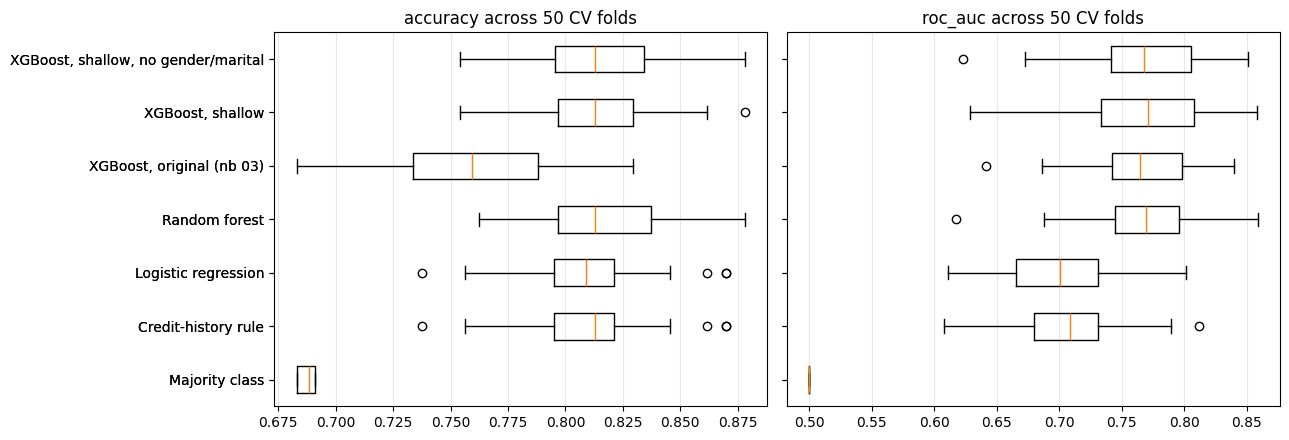

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
names = list(models)
for ax, m in zip(axes, ["accuracy", "roc_auc"]):
    ax.boxplot([fold_scores[n][m] for n in names], vert=False, tick_labels=names)
    ax.set_title(f"{m} across 50 CV folds")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Paired comparison against the credit-history rule

Because every model saw the same 50 splits, the per-fold differences can be compared directly.

In [5]:
paired = []
for name in names:
    if name == "Credit-history rule":
        continue
    for m in ["accuracy", "roc_auc"]:
        d = fold_scores[name][m] - fold_scores["Credit-history rule"][m]
        paired.append({"model": name, "metric": m, "mean_diff": d.mean(),
                       "folds_better": f"{(d > 0).sum()}/{len(d)}", "folds_worse": f"{(d < 0).sum()}/{len(d)}"})
pd.DataFrame(paired).pivot(index="model", columns="metric").round(3)

mean_diff         folds_better          \
metric                               accuracy roc_auc     accuracy roc_auc   
model                                                                        
Logistic regression                    -0.002  -0.002         0/50   25/50   
Majority class                         -0.122  -0.205         0/50    0/50   
Random forest                           0.007   0.059        33/50   49/50   
XGBoost, original (nb 03)              -0.049   0.057         3/50   47/50   
XGBoost, shallow                        0.005   0.063        27/50   49/50   
XGBoost, shallow, no gender/marital     0.005   0.063        28/50   49/50   

                                    folds_worse          
metric                                 accuracy roc_auc  
model                                                    
Logistic regression                        6/50   25/50  
Majority class                            50/50   50/50  
Random forest                              9/50    1/50  
XGBoost, original (nb 03)                 47/50    3/50  
XGBoost, shallow                          11/50    1/50  
XGBoost, shallow, no gender/marital       10/50    1/50

## 3. Fairness audit on out-of-fold predictions

In [6]:
def fnr(y_true, y_pred):
    pos = y_true == 1
    return float(((y_pred == 0) & pos).sum() / pos.sum()) if pos.sum() else 0.0

def group_metrics(y_true, y_pred, gender, married):
    m, f = gender == 1, gender == 0
    mar, sin = married == 1, married == 0
    out = {
        "male_approval_rate": y_pred[m].mean(), "female_approval_rate": y_pred[f].mean(),
        "married_approval_rate": y_pred[mar].mean(), "single_approval_rate": y_pred[sin].mean(),
        "male_fnr": fnr(y_true[m], y_pred[m]), "female_fnr": fnr(y_true[f], y_pred[f]),
    }
    out["gender_disparity"] = abs(out["male_approval_rate"] - out["female_approval_rate"])
    out["married_disparity"] = abs(out["married_approval_rate"] - out["single_approval_rate"])
    out["fnr_disparity"] = abs(out["male_fnr"] - out["female_fnr"])
    # Same weighting as the API's original fairness gate.
    out["bias_score"] = 0.40 * out["gender_disparity"] + 0.40 * out["fnr_disparity"] + 0.20 * out["married_disparity"]
    return out

base_all = clean_raw(raw, fit_fill_values(raw))   # only used to read group membership
gender, married = base_all["Gender"].to_numpy(), base_all["Married"].to_numpy()
print(f"Group sizes: male={int((gender==1).sum())}, female={int((gender==0).sum())}, "
      f"married={int((married==1).sum())}, single={int((married==0).sum())}")

def oof_predictions(model, repeats=10):
    return np.array([cross_val_predict(model, raw, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r))
                     for r in range(repeats)])

Group sizes: male=502, female=112, married=401, single=213


In [7]:
def audit(model, n_boot=1000):
    preds = oof_predictions(model)
    point = pd.DataFrame([group_metrics(y, p, gender, married) for p in preds]).mean()
    rng = np.random.default_rng(SEED)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        p = preds[rng.integers(len(preds))]
        boots.append(group_metrics(y[idx], p[idx], gender[idx], married[idx]))
    boots = pd.DataFrame(boots)
    ci = {k: [float(boots[k].quantile(0.025)), float(boots[k].quantile(0.975))]
          for k in ["gender_disparity", "married_disparity", "fnr_disparity", "bias_score"]}
    return point, ci

audits = {name: audit(models[name]) for name in ["XGBoost, original (nb 03)", "XGBoost, shallow", FINAL]}
cols = ["male_approval_rate", "female_approval_rate", "married_approval_rate", "single_approval_rate",
        "gender_disparity", "married_disparity", "fnr_disparity", "bias_score"]
pd.DataFrame({n: a[0][cols] for n, a in audits.items()}).round(3)

,"XGBoost, original (nb 03)","XGBoost, shallow","XGBoost, shallow, no gender/marital"
male_approval_rate,0.733,0.841,0.841
female_approval_rate,0.643,0.796,0.802
married_approval_rate,0.761,0.840,0.838
single_approval_rate,0.633,0.821,0.826
gender_disparity,0.090,0.045,0.039
married_disparity,0.128,0.020,0.012
fnr_disparity,0.064,0.042,0.035
bias_score,0.087,0.039,0.032


In [8]:
for name, (point, ci) in audits.items():
    print(name)
    for k, (lo, hi) in ci.items():
        print(f"   {k:18s} {point[k]:.3f}   95% CI [{lo:.3f}, {hi:.3f}]")

XGBoost, original (nb 03)
   gender_disparity   0.090   95% CI [0.009, 0.198]
   married_disparity  0.128   95% CI [0.036, 0.212]
   fnr_disparity      0.064   95% CI [0.004, 0.181]
   bias_score         0.087   95% CI [0.026, 0.180]
XGBoost, shallow
   gender_disparity   0.045   95% CI [0.002, 0.141]
   married_disparity  0.020   95% CI [0.002, 0.091]
   fnr_disparity      0.042   95% CI [0.003, 0.119]
   bias_score         0.039   95% CI [0.011, 0.109]
XGBoost, shallow, no gender/marital
   gender_disparity   0.039   95% CI [0.002, 0.128]
   married_disparity  0.012   95% CI [0.001, 0.083]
   fnr_disparity      0.035   95% CI [0.002, 0.111]
   bias_score         0.032   95% CI [0.010, 0.099]


**How to read this.** Gender and marital status still have an *indirect* path into the model even after they are removed as inputs, for example through co-applicant income, which is strongly linked to being married. Removing them does not guarantee equal outcomes, so the audit still measures outcomes by group. The confidence intervals are wide, mostly because the dataset contains only about 110 female applicants.

## 4. Train the final model and write the model report

In [9]:
fills = fit_fill_values(raw)
X_all = engineer(clean_raw(raw, fills), MODEL_FEATURES)
final_model = xgb_shallow().fit(X_all, y)
final_model.save_model("../src/loan_model.json")   # portable JSON, no pickle

point, ci = audits[FINAL]
BIAS_THRESHOLD = 0.20
report = {
    "model_version": f"xgb-shallow-noprot-{date.today().isoformat()}",
    "model": "XGBoost (n_estimators=100, max_depth=2, learning_rate=0.05)",
    "features": MODEL_FEATURES,
    "excluded_features": ["Gender", "Married"],
    "training_rows": int(len(y)),
    "evaluation": {
        "protocol": "Repeated stratified 5-fold CV x 10, preprocessing fitted inside folds",
        "metrics": {m: {"mean": round(float(results.loc[FINAL, f"{m}_mean"]), 4),
                        "std": round(float(results.loc[FINAL, f"{m}_std"]), 4)} for m in metrics},
        "credit_history_rule_baseline": {m: round(float(results.loc["Credit-history rule", f"{m}_mean"]), 4) for m in metrics},
    },
    "fairness_audit": {
        "method": "Out-of-fold predictions (10 x 5-fold), averaged; 95% bootstrap CIs (1000 resamples)",
        "threshold": BIAS_THRESHOLD,
        "bias_score": round(float(point["bias_score"]), 4),
        "passed": bool(point["bias_score"] <= BIAS_THRESHOLD),
        "metrics": {k: round(float(point[k]), 4) for k in cols if k != "bias_score"},
        "confidence_intervals": {k: [round(v, 4) for v in iv] for k, iv in ci.items()},
        "group_sizes": {"male": int((gender == 1).sum()), "female": int((gender == 0).sum()),
                        "married": int((married == 1).sum()), "single": int((married == 0).sum())},
    },
}
with open("../src/model_report.json", "w") as f:
    json.dump(report, f, indent=2)
print(json.dumps(report["evaluation"], indent=2))
print("fairness audit passed:", report["fairness_audit"]["passed"], "| bias score:", report["fairness_audit"]["bias_score"])

{
  "protocol": "Repeated stratified 5-fold CV x 10, preprocessing fitted inside folds",
  "metrics": {
    "accuracy": {
      "mean": 0.8146,
      "std": 0.0277
    },
    "balanced_accuracy": {
      "mean": 0.722,
      "std": 0.0397
    },
    "f1": {
      "mean": 0.878,
      "std": 0.0172
    },
    "roc_auc": {
      "mean": 0.768,
      "std": 0.047
    }
  },
  "credit_history_rule_baseline": {
    "accuracy": 0.8094,
    "balanced_accuracy": 0.7054,
    "f1": 0.8766,
    "roc_auc": 0.7054
  }
}
fairness audit passed: True | bias score: 0.032


## 5. Explanations with TreeSHAP

`pred_contribs=True` returns each feature's additive contribution to the log-odds of approval. Contributions plus the bias term add up exactly to the model's raw output. The API uses the same call to show every applicant the main reasons behind their decision.

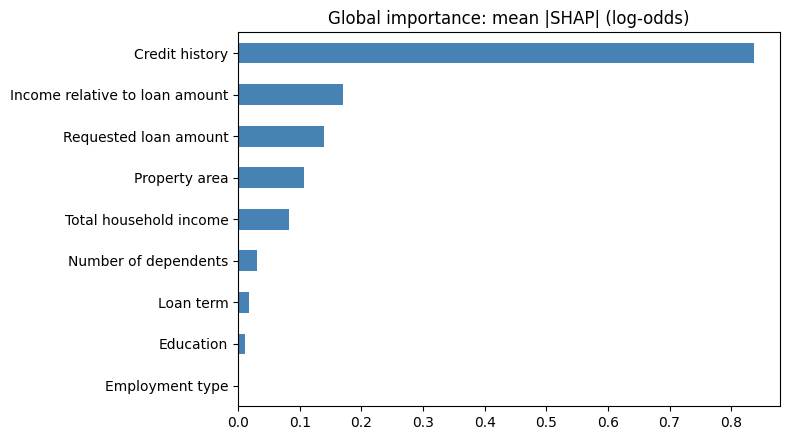

Credit_History          0.837
Income_to_Loan_Ratio    0.171
LoanAmount_Log          0.139
Property_Area           0.107
Total_Income_Log        0.083
Dependents              0.031
Loan_Amount_Term        0.018
Education               0.012
Self_Employed           0.000
dtype: float32

In [10]:
dm = xgb.DMatrix(X_all, feature_names=MODEL_FEATURES)
contribs = final_model.get_booster().predict(dm, pred_contribs=True)   # last column = bias
shap_vals = pd.DataFrame(contribs[:, :-1], columns=MODEL_FEATURES)

# Sanity check: contributions + bias reproduce the model's log-odds
logit = final_model.get_booster().predict(dm, output_margin=True)
assert np.allclose(contribs.sum(axis=1), logit, atol=1e-4)

importance = shap_vals.abs().mean().sort_values()
ax = importance.rename(index=FEATURE_LABELS).plot.barh(figsize=(8, 4.5), color="steelblue")
ax.set_title("Global importance: mean |SHAP| (log-odds)")
plt.tight_layout()
plt.savefig("../docs/screenshots/shap_importance.png", dpi=150)
plt.show()
importance.sort_values(ascending=False).round(3)

In [11]:
print("Mean SHAP of credit history by value:")
print(shap_vals.groupby(X_all["Credit_History"].to_numpy())["Credit_History"].mean().round(3))

i = int(np.argmin(final_model.predict_proba(X_all)[:, 1]))
row = shap_vals.iloc[i].sort_values(key=abs, ascending=False)
print(f"\nExample: applicant #{i}, P(approve) = {final_model.predict_proba(X_all.iloc[[i]])[0, 1]:.3f}")
for f, v in row.head(4).items():
    print(f"   {FEATURE_LABELS[f]:32s} {'raises' if v > 0 else 'lowers'} approval odds ({v:+.3f})")

Mean SHAP of credit history by value:


0.0   -2.788
1.0    0.507
Name: Credit_History, dtype: float32

Example: applicant #168, P(approve) = 0.025
   Credit history                   lowers approval odds (-2.911)
   Total household income           lowers approval odds (-0.842)
   Requested loan amount            lowers approval odds (-0.430)
   Loan term                        lowers approval odds (-0.363)


## 6. Conclusions

1. **The original model was worse than a one-line rule.** The notebook 03 XGBoost reaches 0.760 accuracy against 0.809 for "approve if credit history is good", and loses in 47 of 50 folds. The main cause is `scale_pos_weight = neg/pos ≈ 0.45`, which *down-weights* the approved class. Its single-split test result (0.790) was flattering noise.
2. **Accuracy is limited by the data, not the algorithm.** No candidate beats the credit-history rule by more than about one accuracy point. The final model is +0.5 points and better in 28 of 50 folds, which is not a meaningful difference. Credit history dominates the model: mean |SHAP| is 0.84 against 0.17 for the next feature.
3. **Where the model does add value is ranking.** Tree models reach ROC-AUC ≈ 0.77 against 0.705 for the rule, and win in 49 of 50 folds. Their probabilities separate risk *within* the good-credit group, which a binary rule cannot do. This is what justifies using a model at all.
4. **Gender and marital status can be removed at no cost.** Dropping them leaves accuracy and AUC unchanged (0.815 / 0.768). Every disparity point estimate also falls (bias score 0.087 for the original model → 0.032), though the confidence intervals overlap, so the fairness improvement is suggestive rather than proven. The deployed model therefore does not use either attribute. They are still collected so the audit can measure outcomes by group.
5. **Caveats.** The final model was chosen as the best of seven candidates on the same CV, so its estimate is slightly optimistic. With 614 rows, and only 112 female applicants, every number here carries wide uncertainty. This is an educational model, not a credit-scoring system.

**Deployed:** `src/loan_model.json` (XGBoost, depth 2, 100 trees, without gender and marital status). The CV metrics and fairness audit are in `src/model_report.json`.
